# 150 ans de S&P 500 : rendement, risque et valorisation

Analyse exploratoire de l'indice boursier américain S&P 500 de **1871 à 2026**, à partir des données mensuelles de Robert Shiller
(prix, dividendes, bénéfices, inflation, taux longs).

**Questions étudiées**
1. Combien a vraiment rapporté le marché, une fois l'inflation et les dividendes pris en compte ?
2. À quoi ressemble le risque : distribution des rendements, krachs et temps de récupération ?
3. L'horizon de placement change-t-il la probabilité de perdre de l'argent ?
4. La valorisation de départ (ratio CAPE) aide-t-elle à anticiper les rendements des 10 années suivantes ?

> Note : les prix vont jusqu'en septembre 2026 ; les dividendes, bénéfices et l'inflation s'arrêtent mi-2023 dans la source.
> Les analyses « réelles » (corrigées de l'inflation) et « dividendes réinvestis » s'arrêtent donc à juin 2023.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 14, "axes.titleweight": "bold"})
IMG = Path("images"); IMG.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=110, bbox_inches="tight")

## 1. Chargement et préparation des données

In [2]:
df = pd.read_csv("data/sp500_monthly.csv", parse_dates=["date"]).set_index("date")
print(f"{len(df)} mois, de {df.index.min():%Y-%m} à {df.index.max():%Y-%m}")
print("\nValeurs manquantes par colonne :")
print(df.isna().sum().to_string())
df.tail(3)

1869 mois, de 1871-01 à 2026-09

Valeurs manquantes par colonne :
sp500         0
dividend     39
earnings     39
cpi          36
long_rate    36


,sp500,dividend,earnings,cpi,long_rate
date,,,,,
2026-07-01,7481.34,NaN,NaN,NaN,NaN
2026-08-01,7711.32,NaN,NaN,NaN,NaN
2026-09-01,7669.41,NaN,NaN,NaN,NaN


In [3]:
# Indicateurs dérivés
cpi_ref = df["cpi"].dropna().iloc[-1]                     # prix exprimés en dollars de juin 2023
df["real_price"] = df["sp500"] * cpi_ref / df["cpi"]
df["ret_price"] = df["sp500"].pct_change()                # rendement mensuel hors dividendes
df["ret_total"] = (df["sp500"] + df["dividend"] / 12) / df["sp500"].shift(1) - 1   # dividendes réinvestis
df["inflation"] = df["cpi"].pct_change()
df["ret_total_real"] = (1 + df["ret_total"]) / (1 + df["inflation"]) - 1

full = df.dropna(subset=["ret_total_real"])               # période avec fondamentaux : 1871-02 -> 2023-06
print(f"Période complète (avec dividendes et inflation) : {full.index.min():%Y-%m} -> {full.index.max():%Y-%m}")

Période complète (avec dividendes et inflation) : 1871-02 -> 2023-06


## 2. Combien a rapporté le marché ?

Sur 152 ans, 1 $ est devenu :
  Prix nominal                                 979 $   (soit 4.62% par an)
  Dividendes réinvestis (nominal)          641,812 $   (soit 9.17% par an)
  Dividendes réinvestis (réel)              26,210 $   (soit 6.90% par an)


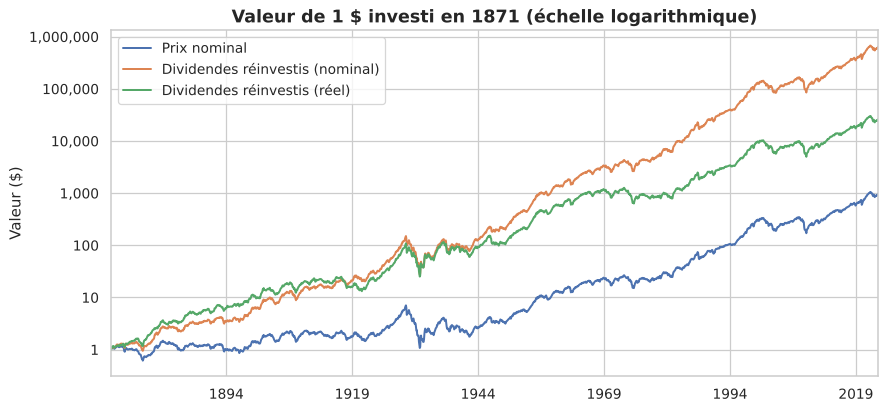

In [4]:
growth = pd.DataFrame({
    "Prix nominal": (1 + full["ret_price"]).cumprod(),
    "Dividendes réinvestis (nominal)": (1 + full["ret_total"]).cumprod(),
    "Dividendes réinvestis (réel)": (1 + full["ret_total_real"]).cumprod(),
})
fig, ax = plt.subplots()
growth.plot(ax=ax, logy=True, lw=1.6)
ax.set_title("Valeur de 1 $ investi en 1871 (échelle logarithmique)")
ax.set_xlabel(""); ax.set_ylabel("Valeur ($)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:.2f}"))
save(fig, "01_croissance_1_dollar")

years = len(full) / 12
cagr = growth.iloc[-1] ** (1 / years) - 1
print(f"Sur {years:.0f} ans, 1 $ est devenu :")
for k in growth: print(f"  {k:35s} {growth[k].iloc[-1]:>12,.0f} $   (soit {cagr[k]:.2%} par an)")

**Lecture** : l'essentiel de la richesse créée vient du **réinvestissement des dividendes**. Le prix seul progresse d'environ 4-5 % par an,
alors que le rendement total dépasse 9 % par an. Une fois l'inflation retirée, il reste environ 6,5-7 % par an de gain réel :
c'est le chiffre à retenir pour un investisseur de long terme.

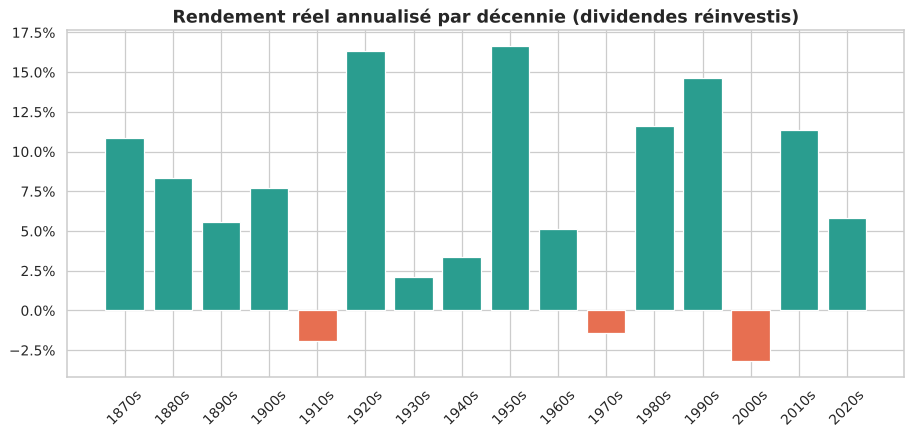

,rendement_total,rendement_reel,inflation
1870s,7.8,10.9,-2.8
1880s,6.0,8.3,-2.2
1890s,5.7,5.6,0.1
1900s,10.3,7.7,2.4
1910s,4.5,-1.9,6.6
1920s,15.2,16.3,-0.9
1930s,0.0,2.1,-2.0
1940s,8.9,3.4,5.4
1950s,19.3,16.7,2.2
1960s,7.8,5.1,2.5


In [5]:
decades = full.groupby((full.index.year // 10) * 10).agg(
    rendement_total=("ret_total", lambda r: (1 + r).prod() ** (12 / len(r)) - 1),
    rendement_reel=("ret_total_real", lambda r: (1 + r).prod() ** (12 / len(r)) - 1),
    inflation=("inflation", lambda r: (1 + r).prod() ** (12 / len(r)) - 1),
)
decades.index = [f"{d}s" for d in decades.index]

fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#2a9d8f" if v >= 0 else "#e76f51" for v in decades["rendement_reel"]]
ax.bar(decades.index, decades["rendement_reel"], color=colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Rendement réel annualisé par décennie (dividendes réinvestis)")
plt.xticks(rotation=45)
save(fig, "02_rendement_par_decennie")
(decades * 100).round(1)   # en %

**Lecture** : les décennies ne se ressemblent pas. Les années 1910, 1970 et 2000 ont été **négatives en termes réels**
(inflation forte ou bulle qui éclate), tandis que les années 1950, 1980 et 1990 ont dépassé 10 % par an.

## 3. Le risque : distribution des rendements mensuels

Rendement mensuel moyen : 0.48% | volatilité mensuelle : 4.05% | volatilité annualisée : 14.0%
Asymétrie (skewness) : 0.37 | kurtosis excédentaire : 16.70
Mois en hausse : 57%


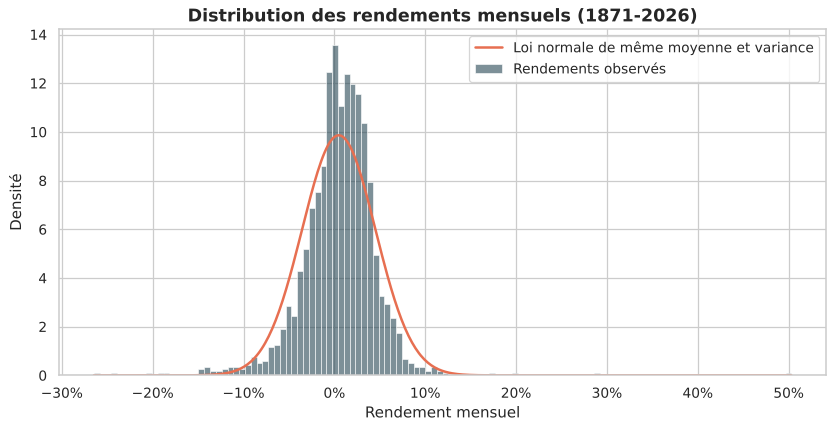

,Pires mois,rendement,Meilleurs mois,rendement
0,1929-11,-26.5,1932-08,50.3
1,1932-04,-24.0,1933-05,28.7
2,2008-10,-20.4,1938-07,19.9
3,2020-03,-19.1,1933-06,17.1
4,1931-12,-18.8,2009-04,12.0


In [6]:
r = df["ret_price"].dropna()                      # prix seuls, jusqu'en 2026
mu, sigma = r.mean(), r.std()
print(f"Rendement mensuel moyen : {mu:.2%} | volatilité mensuelle : {sigma:.2%} | volatilité annualisée : {sigma*np.sqrt(12):.1%}")
print(f"Asymétrie (skewness) : {stats.skew(r):.2f} | kurtosis excédentaire : {stats.kurtosis(r):.2f}")
print(f"Mois en hausse : {(r > 0).mean():.0%}")

fig, ax = plt.subplots()
sns.histplot(r, bins=120, stat="density", ax=ax, color="#264653", alpha=.6, label="Rendements observés")
x = np.linspace(r.min(), r.max(), 400)
ax.plot(x, stats.norm.pdf(x, mu, sigma), color="#e76f51", lw=2, label="Loi normale de même moyenne et variance")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Distribution des rendements mensuels (1871-2026)")
ax.set_xlabel("Rendement mensuel"); ax.set_ylabel("Densité")
ax.legend()
save(fig, "03_distribution_rendements")

extremes = pd.DataFrame({"Pires mois": r.nsmallest(5).index.strftime("%Y-%m"), "rendement ": r.nsmallest(5).values * 100,
                         "Meilleurs mois": r.nlargest(5).index.strftime("%Y-%m"), "rendement": r.nlargest(5).values * 100}).round(1)
extremes

**Lecture** : les rendements ont des **queues épaisses** (kurtosis élevée) : les mois extrêmes, comme les krachs de 1929-1932 ou d'octobre 1987,
sont bien plus fréquents que ne le prévoit une loi normale. Un modèle de risque qui suppose la normalité **sous-estime** le risque de krach.

## 4. Krachs et temps de récupération

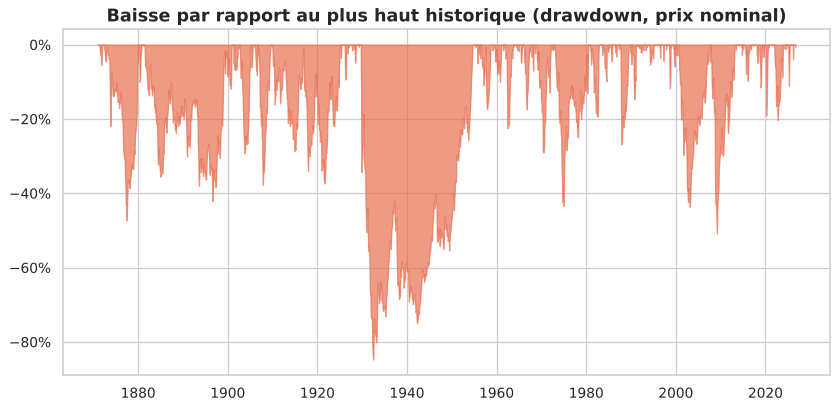

,debut,creux,recuperation,baisse_max,mois_jusquau_creux,mois_pour_recuperer
0,1929-10-01,1932-06-01,1954-09-01,-84.8,32.0,299.0
1,2007-11-01,2009-03-01,2013-03-01,-50.8,16.0,64.0
2,1872-06-01,1877-06-01,1880-02-01,-47.3,60.0,92.0
3,2000-09-01,2003-02-01,2007-05-01,-43.7,29.0,80.0
4,1973-02-01,1974-12-01,1980-07-01,-43.4,22.0,89.0
5,1881-07-01,1896-08-01,1900-12-01,-42.1,181.0,233.0
6,1906-10-01,1907-11-01,1909-08-01,-37.7,13.0,34.0
7,1910-01-01,1921-08-01,1925-01-01,-37.4,139.0,180.0


In [7]:
price = df["sp500"]
peak = price.cummax()
drawdown = price / peak - 1

fig, ax = plt.subplots()
ax.fill_between(drawdown.index, drawdown, 0, color="#e76f51", alpha=.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Baisse par rapport au plus haut historique (drawdown, prix nominal)")
save(fig, "04_drawdowns")

# Identification des grands épisodes de baisse (> 20 %)
episodes, in_dd = [], False
for date, dd in drawdown.items():
    if not in_dd and dd < 0:
        in_dd, start, trough, trough_dd = True, date, date, dd
    elif in_dd:
        if dd < trough_dd: trough, trough_dd = date, dd
        if dd == 0:
            episodes.append((start, trough, date, trough_dd)); in_dd = False
if in_dd: episodes.append((start, trough, pd.NaT, trough_dd))

ep = pd.DataFrame(episodes, columns=["debut", "creux", "recuperation", "baisse_max"])
ep = ep[ep["baisse_max"] < -0.20].copy()
ep["mois_jusquau_creux"] = ((ep["creux"] - ep["debut"]).dt.days / 30.44).round()
ep["mois_pour_recuperer"] = ((ep["recuperation"] - ep["debut"]).dt.days / 30.44).round()
ep["baisse_max"] = (ep["baisse_max"] * 100).round(1)
ep.sort_values("baisse_max").head(8).reset_index(drop=True)

**Lecture** : le krach de 1929 reste hors norme (environ -80 %, près de 25 ans pour retrouver le sommet en nominal).
Les crises plus récentes (2000, 2008) ont aussi demandé **plusieurs années** pour être effacées : la patience fait partie du rendement.

## 5. L'horizon de placement réduit-il le risque ?

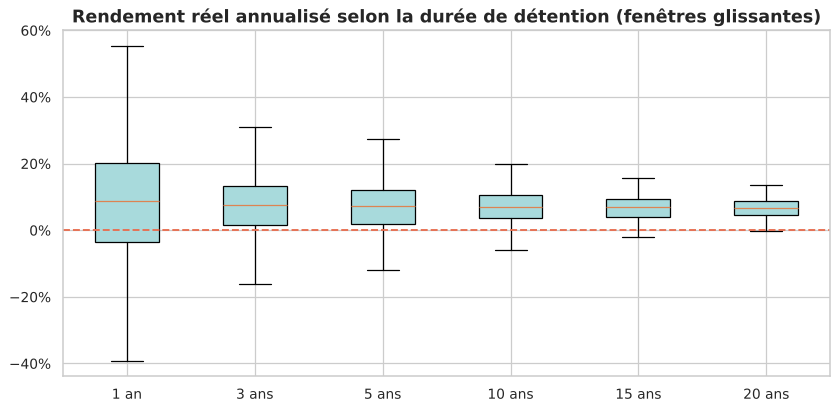

,proba. de perte réelle,pire rendement annualisé,médiane,meilleur
horizon (ans),,,,
1,31.1,-58.1,8.6,151.3
3,21.6,-35.2,7.6,39.2
5,19.0,-13.2,7.2,33.3
10,11.3,-5.9,6.9,20.0
15,4.5,-2.1,6.9,15.6
20,0.1,-0.2,6.7,13.6


In [8]:
horizons = [1, 3, 5, 10, 15, 20]
log_r = np.log1p(full["ret_total_real"])
rows, rolling = [], {}
for h in horizons:
    ann = np.expm1(log_r.rolling(12 * h).sum() / h).dropna()
    rolling[h] = ann
    rows.append({"horizon (ans)": h, "proba. de perte réelle": (ann < 0).mean(),
                 "pire rendement annualisé": ann.min(), "médiane": ann.median(), "meilleur": ann.max()})
risk = pd.DataFrame(rows).set_index("horizon (ans)")

fig, ax = plt.subplots()
ax.boxplot([rolling[h] for h in horizons], tick_labels=[f"{h} an{'s' if h > 1 else ''}" for h in horizons],
           showfliers=False, patch_artist=True, boxprops=dict(facecolor="#a8dadc"))
ax.axhline(0, color="#e76f51", lw=1.5, ls="--")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Rendement réel annualisé selon la durée de détention (fenêtres glissantes)")
save(fig, "05_horizon_risque")
(risk * 100).round(1)

**Lecture** : sur 1 an, on perd de l'argent (en réel) environ **une fois sur trois**. Sur 20 ans, elle tombe à **quasiment zéro** (0,1 % des fenêtres) :
la dispersion des rendements annualisés se resserre fortement avec l'horizon.

## 6. La valorisation de départ prédit-elle les rendements futurs ?

Corrélation de Spearman : -0.49 (p-value 4.9e-98) | R² de la régression : 0.29


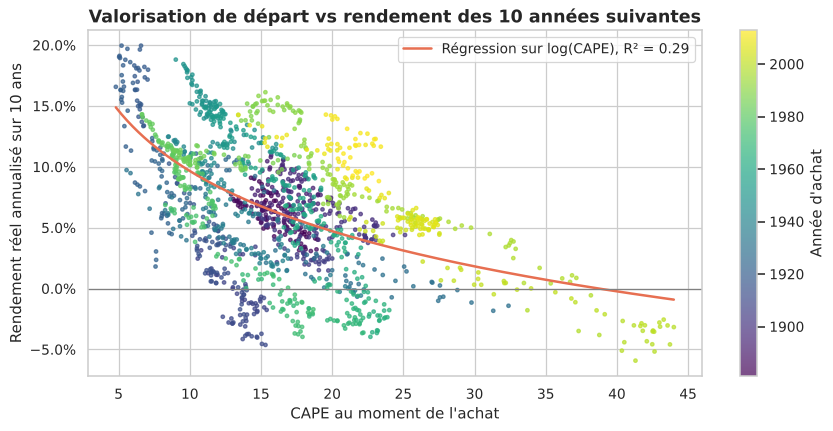

,mean,min,max
quintile CAPE,,,
1 (bon marché),10.9,1.8,20.0
2,7.2,-4.2,15.8
3,6.6,-4.6,16.1
4,5.6,-4.0,14.6
5 (cher),2.9,-5.9,13.1


In [9]:
# CAPE (Shiller P/E) : prix réel / moyenne sur 10 ans des bénéfices réels
real_earn = full["earnings"] * cpi_ref / full["cpi"]
cape = (full["real_price"] / real_earn.rolling(120).mean()).dropna()
fwd10 = np.expm1(log_r[::-1].rolling(120).sum()[::-1].shift(-1) / 10)   # rendement réel annualisé des 10 ans suivants
val = pd.concat([cape.rename("CAPE"), fwd10.rename("rendement_10_ans")], axis=1, sort=True).dropna()

rho, p = stats.spearmanr(val["CAPE"], val["rendement_10_ans"])
slope, intercept, r_val, *_ = stats.linregress(np.log(val["CAPE"]), val["rendement_10_ans"])

fig, ax = plt.subplots()
sc = ax.scatter(val["CAPE"], val["rendement_10_ans"], c=val.index.year, cmap="viridis", s=8, alpha=.7)
xs = np.linspace(val["CAPE"].min(), val["CAPE"].max(), 200)
ax.plot(xs, intercept + slope * np.log(xs), color="#e76f51", lw=2, label=f"Régression sur log(CAPE), R² = {r_val**2:.2f}")
ax.axhline(0, color="grey", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("CAPE au moment de l'achat"); ax.set_ylabel("Rendement réel annualisé sur 10 ans")
ax.set_title("Valorisation de départ vs rendement des 10 années suivantes")
fig.colorbar(sc, label="Année d'achat"); ax.legend()
save(fig, "06_cape_vs_rendement")
print(f"Corrélation de Spearman : {rho:.2f} (p-value {p:.1e}) | R² de la régression : {r_val**2:.2f}")

val["quintile CAPE"] = pd.qcut(val["CAPE"], 5, labels=["1 (bon marché)", "2", "3", "4", "5 (cher)"])
val.groupby("quintile CAPE", observed=True)["rendement_10_ans"].agg(["mean", "min", "max"]).mul(100).round(1)

In [10]:
print(f"Dernier CAPE disponible ({cape.index[-1]:%Y-%m}) : {cape.iloc[-1]:.1f}  | moyenne historique : {cape.mean():.1f}")

Dernier CAPE disponible (2023-06) : 29.8  | moyenne historique : 17.3


**Lecture** : plus le marché est cher à l'achat (CAPE élevé), plus les rendements des 10 années suivantes ont été faibles.
La relation est nette en moyenne (corrélation de rang ≈ -0,5, rendement moyen de 11 % par an dans le quintile le moins cher contre 3 % dans le plus cher), mais elle **ne sert pas au market timing à court terme** :
un marché cher peut le rester longtemps. En 2023, le CAPE se situait nettement au-dessus de sa moyenne historique.

## Conclusions

| Question | Réponse courte |
|---|---|
| Rendement de long terme | ≈ 9 % par an dividendes réinvestis, ≈ 6,5-7 % après inflation |
| Rôle des dividendes | Majeur : sans eux, la richesse finale est plusieurs centaines de fois plus faible |
| Risque | Queues épaisses : les krachs sont plus fréquents que ne le prévoit une loi normale |
| Horizon | Perte réelle ≈ 1 fois sur 3 à 1 an, quasiment jamais sur 20 ans |
| Valorisation | Un CAPE élevé annonce en moyenne des rendements à 10 ans plus faibles |

*Limites* : un seul marché (États-Unis, gagnant du XXe siècle : biais du survivant), pas de frais ni d'impôts,
données mensuelles (les krachs intra-mois sont lissés).